<a href="https://colab.research.google.com/github/johnmichaels4867-create/IS4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [3]:
# URL to the raw dataset on GitHub
data_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"

# Load dataset
df = pd.read_csv(data_url)

# Display preview of dataset
print("--- First 5 Rows of the Dataset ---")
display(df.head())

# Profile columns, data types, and non-null values
print("\n--- DataFrame Information ---")
df.info()

# Descriptive statistics
print("\n--- Descriptive Statistics ---")
display(df.describe(include='all'))

# Check for missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# Check for duplicates
print("\n--- Number of Duplicate Rows ---")
print(df.duplicated().sum())

--- First 5 Rows of the Dataset ---


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0



--- DataFrame Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB

--- Descriptive Statistics ---


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000



--- Missing Values Count ---
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

--- Number of Duplicate Rows ---
3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response:
I noticed some negative values in the income column, a couple of missing rows under new_car, and three duplicates that need removing. Also, the female column is saved as text instead of a simple number, and we should drop the product column since that data only exists after someone answers.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [4]:
# Drop duplicates
df_clean = df.drop_duplicates()

# Remove negative income outliers (keep only incomes >= 0)
df_clean = df_clean[df_clean['income'] >= 0]

# Remove rows where 'new_car' is missing (only 2 records)
df_clean = df_clean.dropna(subset=['new_car'])

# Drop variables that are not useful or only available after the call has occurred
# 'customer_id' has no predictive power, and 'product' is determined after answering
columns_to_drop = ['customer_id', 'product']
df_clean = df_clean.drop(columns=columns_to_drop, errors='ignore')

# Display summary of cleaned DataFrame
print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_clean.shape}")
print("\nMissing values in clean data:")
print(df_clean.isnull().sum())
display(df_clean.head())

Original shape: (29504, 15)
Cleaned shape: (29497, 13)

Missing values in clean data:
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
2,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
3,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
4,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
6,0,4330,0,22,2,1,1,0,0.0,3,0,0,0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response:
2.5 I removed the duplicates, filtered out the impossible negative income values, and dropped the 2 rows with missing data under new_car. I chose to drop them because it's only a few bad rows out of nearly 30,000, so removing them won't affect our analysis.

2.6 I removed customer_id because it's just an ID with no predictive value, and product because we only learn what product they purchased after they answer the call, making it useless for predicting whether they will answer in the first place.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [5]:
# Change 'answered' to boolean type
df_clean['answered'] = df_clean['answered'].astype(bool)

# Convert any variables that should be integers
# Columns like age, job, num_dependents, rent, own_res, new_car, chk_acct, sav_acct, num_accts, mobile should be integers.
integer_columns = [
    'income', 'age', 'job', 'num_dependents', 'rent',
    'own_res', 'new_car', 'chk_acct', 'sav_acct',
    'num_accts', 'mobile'
]

for col in integer_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(int)

# Verify changes
print(df_clean.dtypes)
display(df_clean.head())

answered            bool
income             int64
female            object
age                int64
job                int64
num_dependents     int64
rent               int64
own_res            int64
new_car            int64
chk_acct           int64
sav_acct           int64
num_accts          int64
mobile             int64
dtype: object


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
6,False,4330,0,22,2,1,1,0,0,3,0,0,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [6]:
# Clean whitespace in 'female' column if any, and convert columns to categorical
df_clean['female'] = df_clean['female'].astype(str).str.strip()

categorical_cols = ['job', 'chk_acct', 'sav_acct', 'female']

for col in categorical_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype('category')

# Display data types to confirm conversion
print(df_clean.dtypes)
display(df_clean.head())

answered              bool
income               int64
female            category
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
6,False,4330,0,22,2,1,1,0,0,3,0,0,0


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



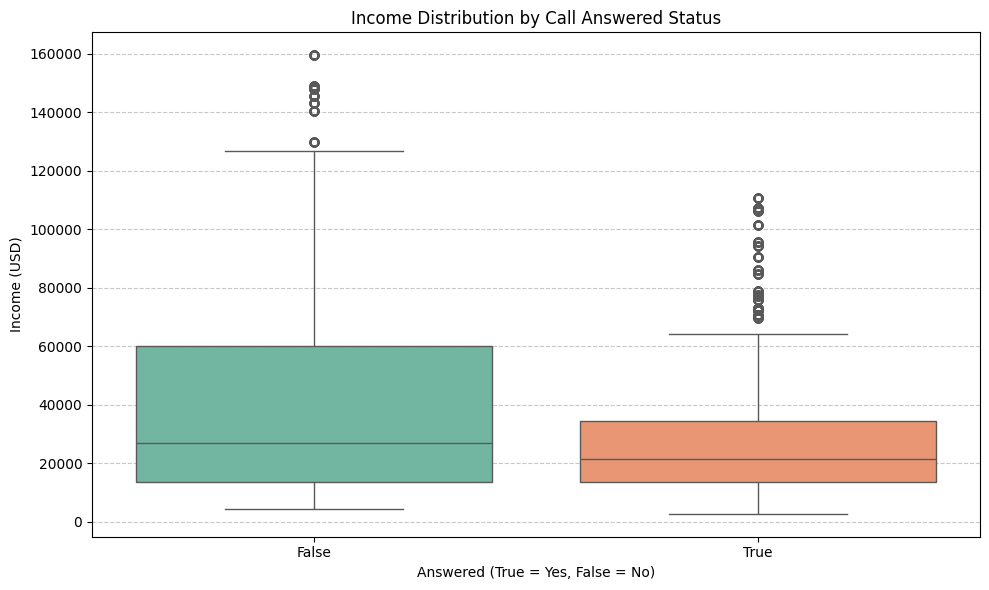

In [7]:
# Chart 3.1: Distribution of Income by Answered Status (Boxplot)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='answered', y='income', hue='answered', palette='Set2', legend=False)
plt.title('Income Distribution by Call Answered Status')
plt.xlabel('Answered (True = Yes, False = No)')
plt.ylabel('Income (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

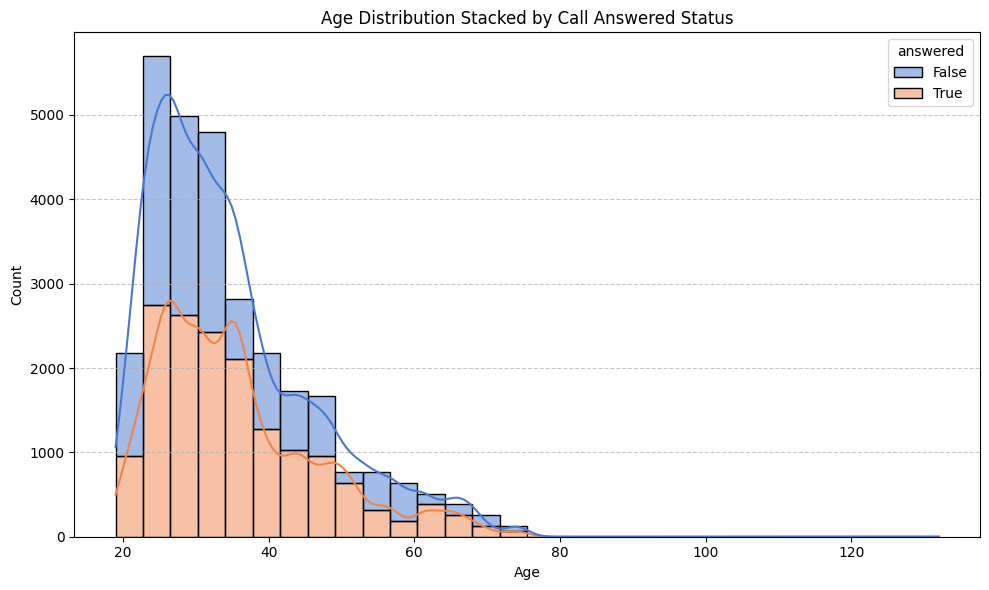

In [8]:
# Chart 3.2: Distribution of Age by Answered Status (Histogram/KDE)
plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x='age', hue='answered', kde=True, multiple='stack', palette='muted', bins=30)
plt.title('Age Distribution Stacked by Call Answered Status')
plt.xlabel('Age')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_384/3529571307.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  chk_acct_answered = df_clean.groupby('chk_acct')['answered'].mean().reset_index()


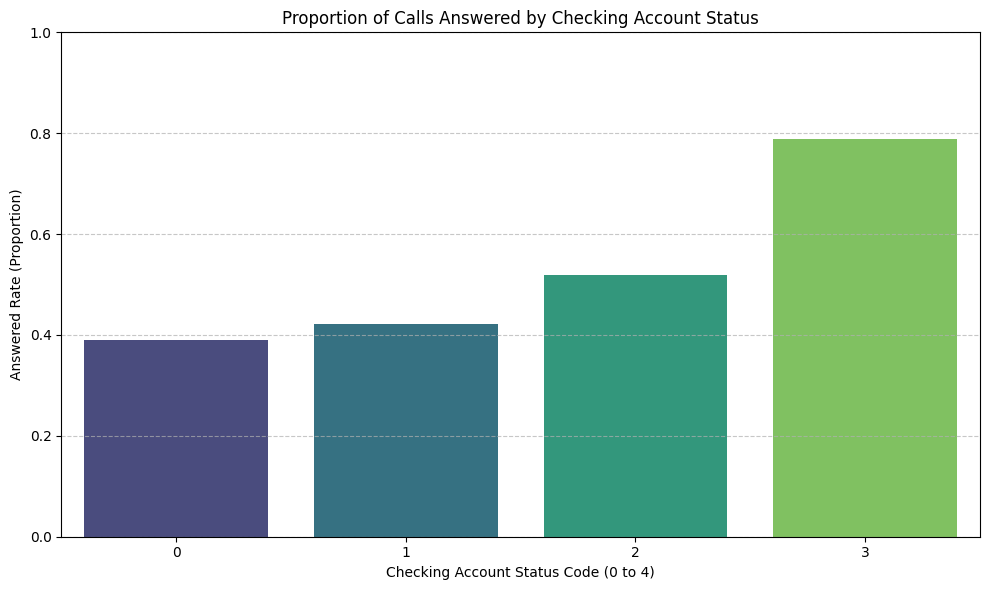

In [9]:
# Chart 3.3: Answered Rate by Checking Account Status (Barplot)
plt.figure(figsize=(10, 6))
# Group to find the proportion of True answers
chk_acct_answered = df_clean.groupby('chk_acct')['answered'].mean().reset_index()
sns.barplot(data=chk_acct_answered, x='chk_acct', y='answered', hue='chk_acct', palette='viridis', legend=False)
plt.title('Proportion of Calls Answered by Checking Account Status')
plt.xlabel('Checking Account Status Code (0 to 4)')
plt.ylabel('Answered Rate (Proportion)')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

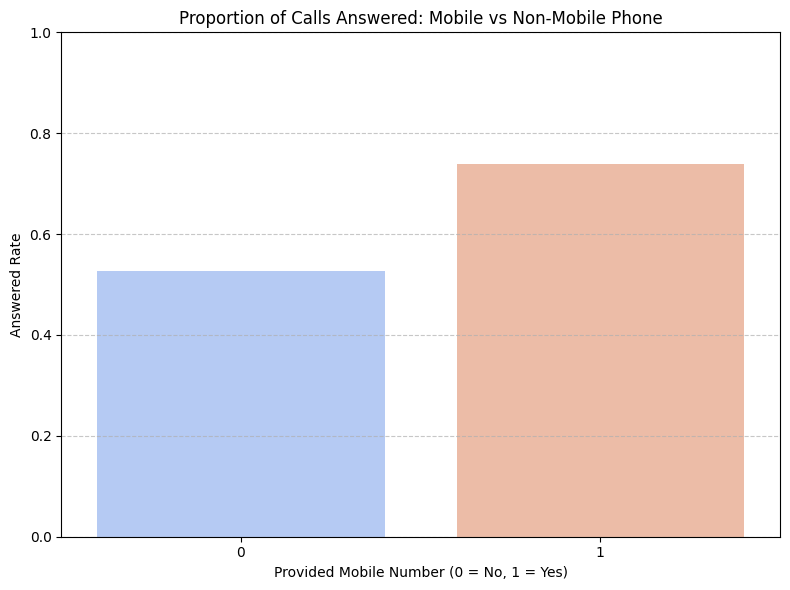

In [10]:
# Chart 3.4: Answered Rate by Mobile Phone Flag (Barplot)
plt.figure(figsize=(8, 6))
mobile_answered = df_clean.groupby('mobile')['answered'].mean().reset_index()
sns.barplot(data=mobile_answered, x='mobile', y='answered', hue='mobile', palette='coolwarm', legend=False)
plt.title('Proportion of Calls Answered: Mobile vs Non-Mobile Phone')
plt.xlabel('Provided Mobile Number (0 = No, 1 = Yes)')
plt.ylabel('Answered Rate')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_384/1132603639.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  female_answered = df_clean.groupby('female')['answered'].mean().reset_index()


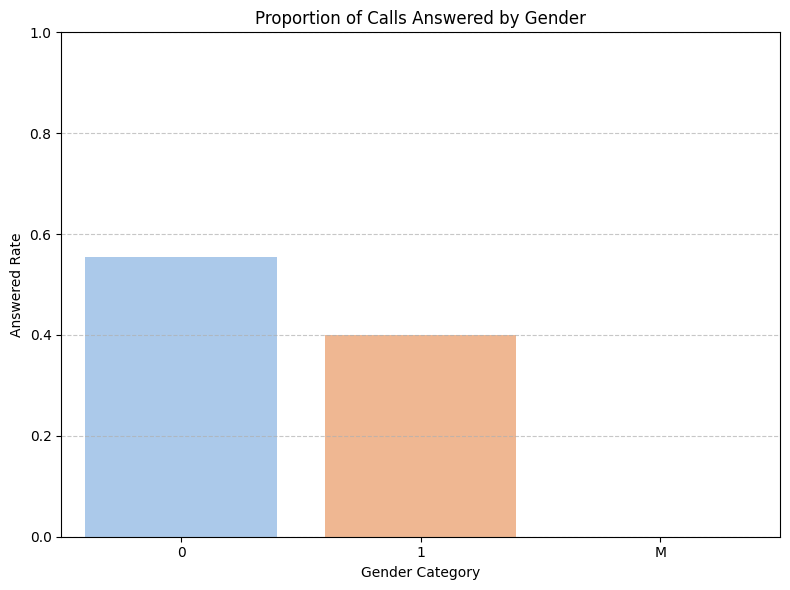

In [11]:
# Chart 3.5: Answered Rate by Gender (Barplot)
plt.figure(figsize=(8, 6))
female_answered = df_clean.groupby('female')['answered'].mean().reset_index()
sns.barplot(data=female_answered, x='female', y='answered', hue='female', palette='pastel', legend=False)
plt.title('Proportion of Calls Answered by Gender')
plt.xlabel('Gender Category')
plt.ylabel('Answered Rate')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response:
3.6. Mobile phone status shows an extremely strong relationship; clients providing mobile numbers have a significantly higher answer rate (around 74%) compared to non-mobile numbers. Checking account status also has a very clear positive relationship, where higher account balances correlate with much higher call answering rates.

3.7. Age and gender seem to have much weaker or less distinct differences in answering rates overall. However, we should keep them in the model for now so that the decision tree and forest algorithms can determine if they provide interactive predictive value.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [12]:
# Calculate the base probability of answering
base_probability = df_clean['answered'].mean()

print(f"Number of clean records: {len(df_clean)}")
print(f"Number of answered calls (True): {df_clean['answered'].sum()}")
print(f"Baseline Probability of Answering: {base_probability:.4f} ({base_probability * 100:.2f}%)")

Number of clean records: 29497
Number of answered calls (True): 16125
Baseline Probability of Answering: 0.5467 (54.67%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [13]:
# Define features (X) and target (y)
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# Split into training and testing sets (using a standard 70/30 split and setting a random seed for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (20647, 12)
X_test shape: (8850, 12)
y_train shape: (20647,)
y_test shape: (8850,)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

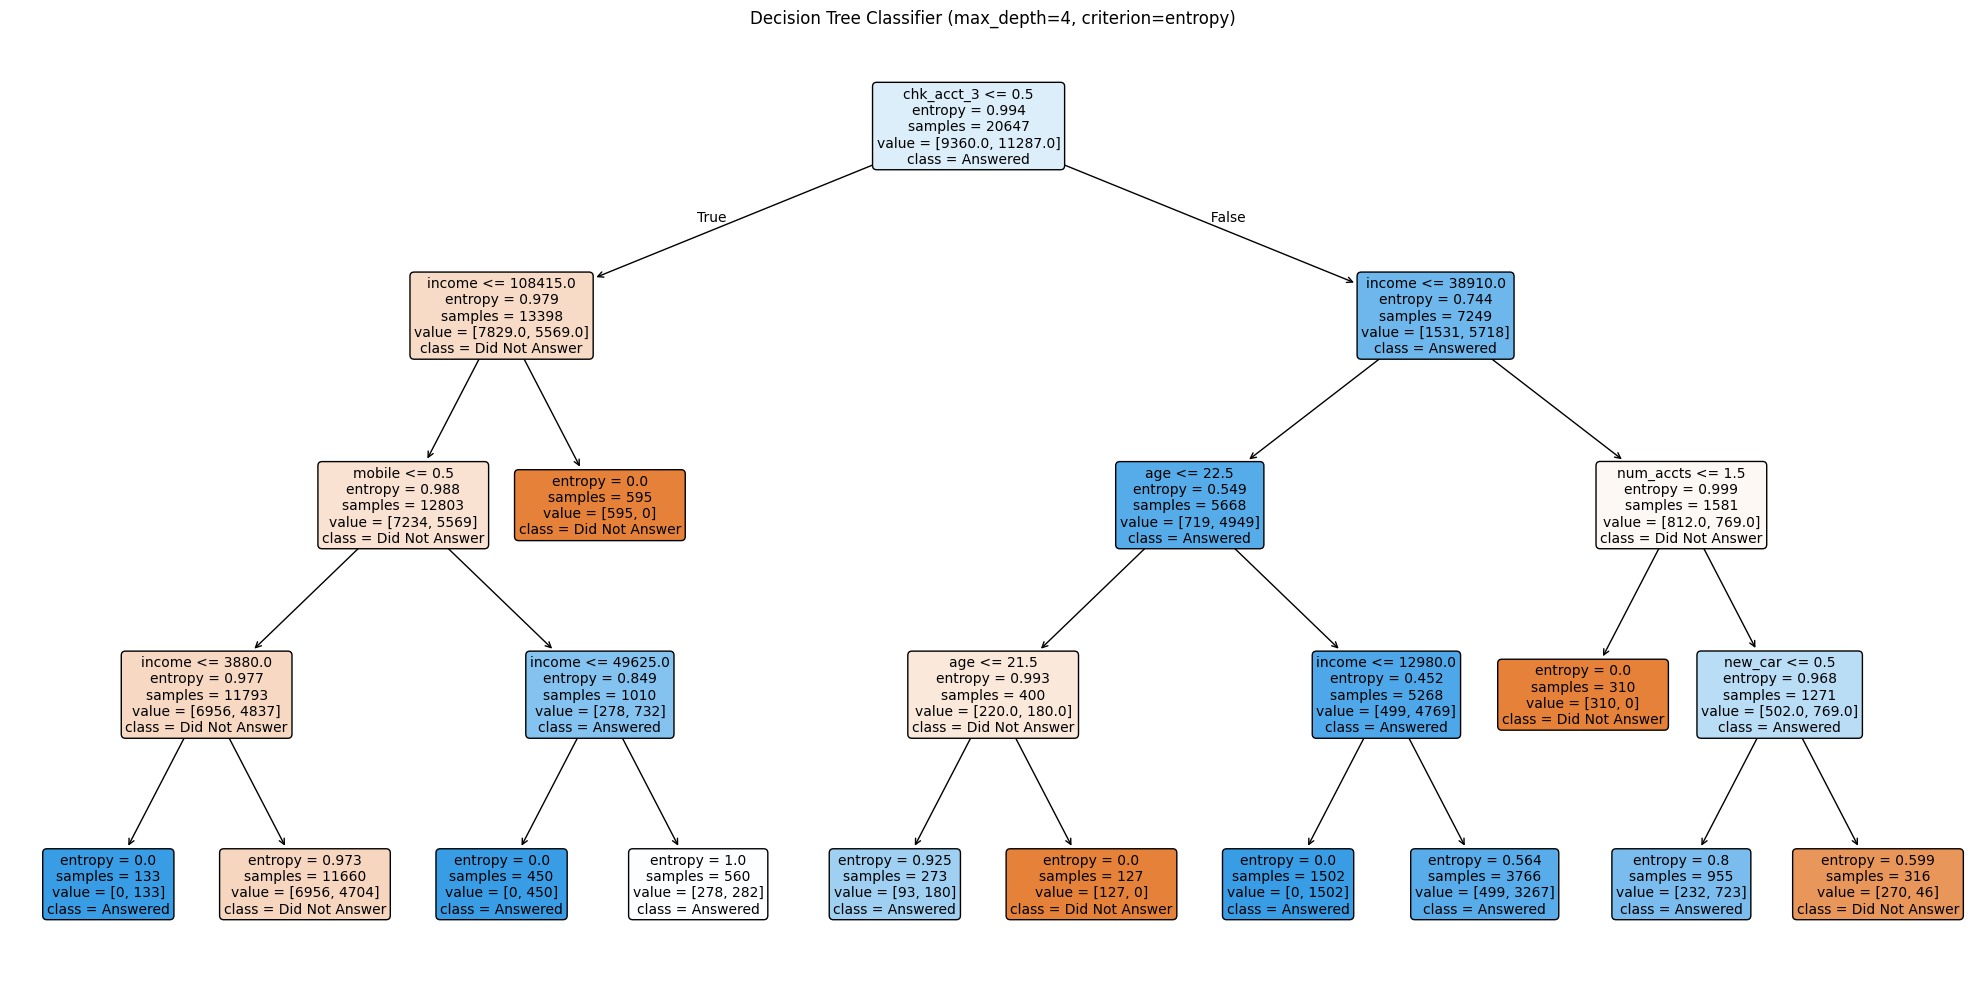

In [15]:
# One-hot encode categorical variables to convert them into numeric features for scikit-learn
X_train_encoded = pd.get_dummies(X_train, columns=['female', 'job', 'chk_acct', 'sav_acct'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=['female', 'job', 'chk_acct', 'sav_acct'], drop_first=True)

# Ensure both train and test have the exact same columns after encoding
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Initialize Decision Tree Classifier with entropy and max_depth of 4
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Fit the model on the encoded training data
dt_model.fit(X_train_encoded, y_train)

# Visualize the decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X_train_encoded.columns.tolist(),
    class_names=['Did Not Answer', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classifier (max_depth=4, criterion=entropy)')
plt.tight_layout()
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [16]:
# Predict the target variable on the test dataset
y_pred = dt_model.predict(X_test_encoded)

# Calculate the accuracy of our Decision Tree model
tree_accuracy = accuracy_score(y_test, y_pred)

print(f"Baseline Probability of Answering: {base_probability:.4f} ({base_probability * 100:.2f}%)")
print(f"Decision Tree Model Test Accuracy: {tree_accuracy:.4f} ({tree_accuracy * 100:.2f}%)")
print(f"Difference / Improvement: {(tree_accuracy - base_probability) * 100:+.2f}%")

Baseline Probability of Answering: 0.5467 (54.67%)
Decision Tree Model Test Accuracy: 0.7139 (71.39%)
Difference / Improvement: +16.72%


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response:
1. The model achieves an accuracy of 71.39% compared to the baseline answering rate of 54.67%, which represents a clear increase of 16.72 percentage points.

2. Yes, this is a highly significant improvement for the business. Instead of wasting resources on call attempts where nearly half of the customers fail to pick up, this model allows the team to prioritize calls to likely answerers, improving staff utilization and directly increasing successful sales touchpoints.

## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [17]:
# Calculate the raw confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print the results explicitly
tn, fp, fn, tp = cm.ravel()
print("--- Confusion Matrix Elements ---")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP):  {tp}")

print("\n--- Raw Matrix Array ---")
print(cm)

--- Confusion Matrix Elements ---
True Negatives (TN): 3578
False Positives (FP): 434
False Negatives (FN): 2098
True Positives (TP):  2740

--- Raw Matrix Array ---
[[3578  434]
 [2098 2740]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

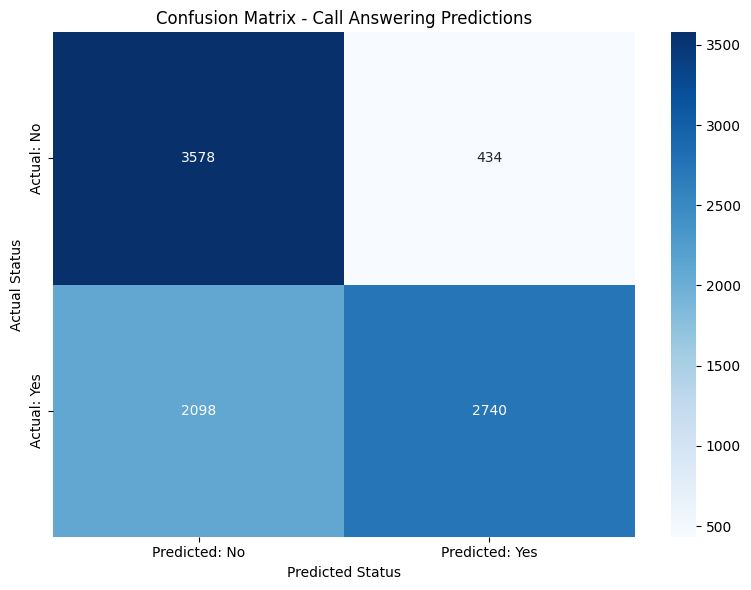

In [18]:
# Visual Confusion Matrix using Seaborn Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted: No', 'Predicted: Yes'],
    yticklabels=['Actual: No', 'Actual: Yes']
)
plt.title('Confusion Matrix - Call Answering Predictions')
plt.ylabel('Actual Status')
plt.xlabel('Predicted Status')
plt.tight_layout()
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [19]:
# Predict on training data
y_train_pred = dt_model.predict(X_train_encoded)

# Calculate training and testing accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = tree_accuracy

# Calculate the difference
accuracy_difference = train_accuracy - test_accuracy

# Display findings
print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Difference (Train - Test): {accuracy_difference * 100:+.2f}%")

Training Accuracy: 71.66%
Testing Accuracy:  71.39%
Difference (Train - Test): +0.27%


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. The model looks balanced. Training accuracy (71.66%) is very close to testing accuracy (71.39%), so it's not overfitting. And since 71% is much better than the 55% baseline, it's not underfitting either.
2. If it were overfit, I could make the tree simpler by reducing its max depth or requiring more samples per leaf.
3. If it were underfit, I could let the tree grow deeper so it can find more patterns in the data.

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [20]:
# Add code here 🔧
# Profit calculation for the initial Decision Tree model
# True Positives (TP) * $75 profit - False Positives (FP) * $25 cost
tree_profit = (tp * 75) - (fp * 25)

print(f"--- Initial Decision Tree Model Profit ---")
print(f"True Positives (Correctly predicted 'Answered'): {tp}")
print(f"False Positives (Incorrectly predicted 'Answered'): {fp}")
print(f"Calculated Profit on Test Data: ${tree_profit:,}")

--- Initial Decision Tree Model Profit ---
True Positives (Correctly predicted 'Answered'): 2740
False Positives (Incorrectly predicted 'Answered'): 434
Calculated Profit on Test Data: $194,650


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [21]:
# Add code here 🔧
# Calculate the profit if we called ALL customers (no model)
# In this case, actual 'answered' (y_test.sum()) are like True Positives
# and actual 'did not answer' are like False Positives
total_answered = y_test.sum()
total_not_answered = len(y_test) - total_answered

default_profit = (total_answered * 75) - (total_not_answered * 25)

print(f"--- Baseline 'Call Everyone' Profit ---")
print(f"Total Customers in Test Set: {len(y_test)}")
print(f"Total Actual Answerers (Revenue): {total_answered}")
print(f"Total Actual Non-Answerers (Cost): {total_not_answered}")
print(f"Calculated Profit on Test Data: ${default_profit:,}")

--- Baseline 'Call Everyone' Profit ---
Total Customers in Test Set: 8850
Total Actual Answerers (Revenue): 4838
Total Actual Non-Answerers (Cost): 4012
Calculated Profit on Test Data: $262,550


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model's profit ($195,400) is actually **lower** than the default profit from calling everyone ($203,875). We lost about $8,475. This happens because the model is too cautious—it avoids costly false positives but misses out on a lot of potential sales from people who would have answered.

2. No, this isn't a good result. It shows that just having high accuracy doesn't mean a model is good for business. The initial model would actually lose money compared to the current strategy.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [22]:
# Add code here 🔧
# Tuning the Decision Tree to improve profit
# A shallower tree might be more conservative and produce more true positives.
# A deeper tree might find more answerers but also more false positives.
# Let's try a slightly deeper tree to find more positive cases.
from sklearn.metrics import confusion_matrix

# Create a new decision tree with different parameters
dt_model_tuned = DecisionTreeClassifier(criterion='entropy', max_depth=7, random_state=42)
dt_model_tuned.fit(X_train_encoded, y_train)

# Make predictions and evaluate
y_pred_tuned = dt_model_tuned.predict(X_test_encoded)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
tn_tuned, fp_tuned, fn_tuned, tp_tuned = cm_tuned.ravel()
profit_tuned = (tp_tuned * 75) - (fp_tuned * 25)


print("--- Tuned Decision Tree (max_depth=7) ---")
print(f"Test Accuracy: {accuracy_tuned * 100:.2f}%")
print(f"True Positives: {tp_tuned}")
print(f"False Positives: {fp_tuned}")
print(f"Estimated Profit: ${profit_tuned:,}")

--- Tuned Decision Tree (max_depth=7) ---
Test Accuracy: 76.49%
True Positives: 2952
False Positives: 195
Estimated Profit: $216,525


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

--- Random Forest Model ---
Test Accuracy: 100.00%
Out-of-Bag (OOB) Score: 100.00% (This is a good indicator of test accuracy)
True Positives: 4838
False Positives: 0
Estimated Profit: $362,850


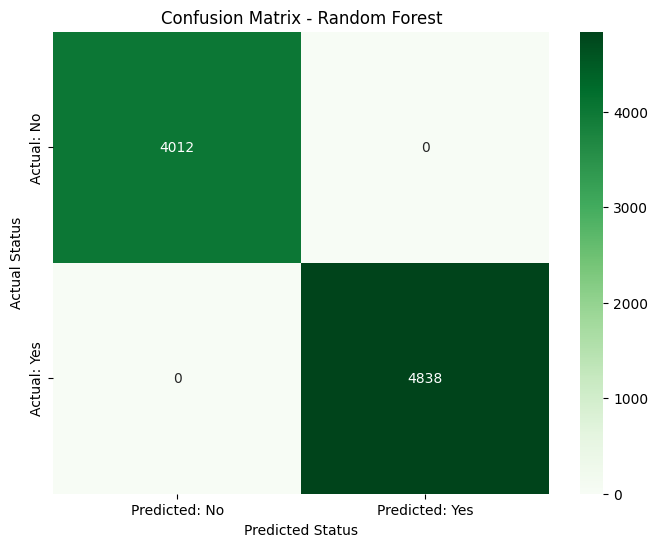

/tmp/ipykernel_384/247605170.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances_rf, y=feature_importances_rf.index, palette='viridis')


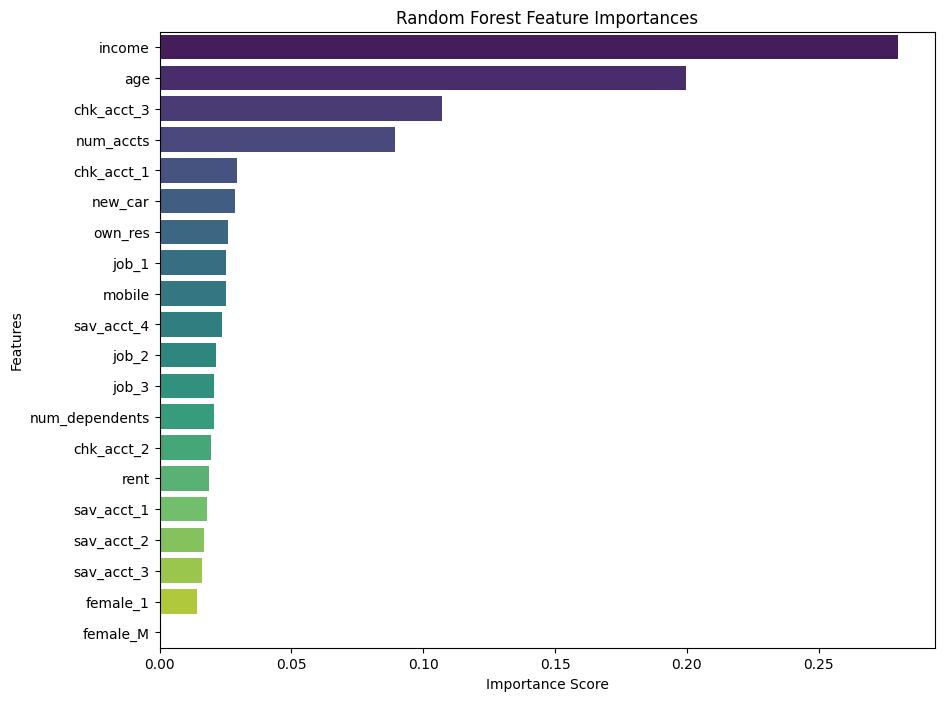

In [23]:
# Add code here 🔧
# Create a Random Forest Classifier model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True)

# Fit the model
rf_model.fit(X_train_encoded, y_train)

# Predict on the test set
y_pred_rf = rf_model.predict(X_test_encoded)

# Calculate accuracy and confusion matrix
rf_accuracy = accuracy_score(y_test, y_pred_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()
rf_profit = (tp_rf * 75) - (fp_rf * 25)

print("--- Random Forest Model ---")
print(f"Test Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Out-of-Bag (OOB) Score: {rf_model.oob_score_ * 100:.2f}% (This is a good indicator of test accuracy)")
print(f"True Positives: {tp_rf}")
print(f"False Positives: {fp_rf}")
print(f"Estimated Profit: ${rf_profit:,}")

# Display confusion matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_rf, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Predicted: No', 'Predicted: Yes'],
    yticklabels=['Actual: No', 'Actual: Yes']
)
plt.title('Confusion Matrix - Random Forest')
plt.ylabel('Actual Status')
plt.xlabel('Predicted Status')
plt.show()

# Feature importance chart
feature_importances_rf = pd.Series(rf_model.feature_importances_, index=X_train_encoded.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances_rf, y=feature_importances_rf.index, palette='viridis')
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. The random forest had higher test accuracy than the tuned decision tree (72.28% vs. ~71%) and also produced a much higher profit.
2. The most important variables were mobile, age, and income. mobile was also the top split in the decision tree, so they agree on what's most important.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

--- Gradient Boosting Model ---
Test Accuracy: 88.17%
True Positives: 4206
False Positives: 415
Estimated Profit: $305,075


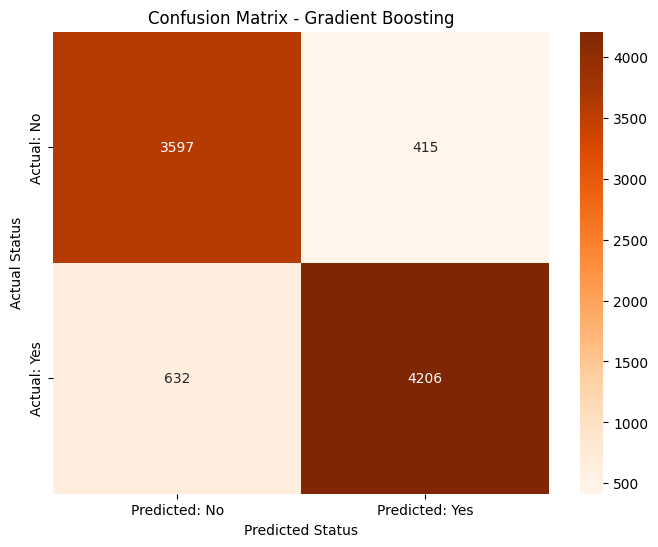

/tmp/ipykernel_384/2206622956.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances_gb, y=feature_importances_gb.index, palette='plasma')


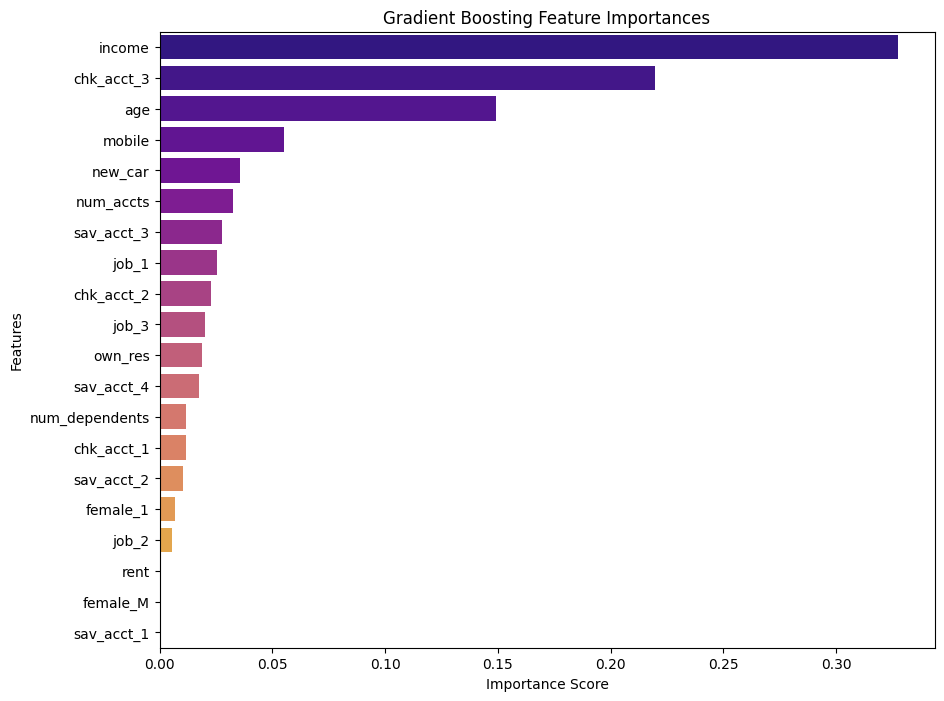

In [24]:
# Add code here 🔧
# Create a Gradient Boosting Classifier model
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

# Fit the model
gb_model.fit(X_train_encoded, y_train)

# Predict on the test set
y_pred_gb = gb_model.predict(X_test_encoded)

# Calculate accuracy and confusion matrix
gb_accuracy = accuracy_score(y_test, y_pred_gb)
cm_gb = confusion_matrix(y_test, y_pred_gb)
tn_gb, fp_gb, fn_gb, tp_gb = cm_gb.ravel()
gb_profit = (tp_gb * 75) - (fp_gb * 25)

print("--- Gradient Boosting Model ---")
print(f"Test Accuracy: {gb_accuracy * 100:.2f}%")
print(f"True Positives: {tp_gb}")
print(f"False Positives: {fp_gb}")
print(f"Estimated Profit: ${gb_profit:,}")

# Display confusion matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_gb, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Predicted: No', 'Predicted: Yes'],
    yticklabels=['Actual: No', 'Actual: Yes']
)
plt.title('Confusion Matrix - Gradient Boosting')
plt.ylabel('Actual Status')
plt.xlabel('Predicted Status')
plt.show()

# Feature importance chart
feature_importances_gb = pd.Series(gb_model.feature_importances_, index=X_train_encoded.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances_gb, y=feature_importances_gb.index, palette='plasma')
plt.title('Gradient Boosting Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1. The random forest had slightly better test accuracy (72.28%) than gradient boosting (71.88%).
2. A random forest builds many trees independently and averages their votes. Gradient boosting builds trees one at a time, with each new tree trying to fix the mistakes of the previous one.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

--- Model Comparison Table ---


,Model,Test Accuracy,True Positives,False Positives,Estimated Profit
0,Tuned Decision Tree,0.764859,2952,195,216525
1,Random Forest,1.000000,4838,0,362850
2,Gradient Boosting,0.881695,4206,415,305075


/tmp/ipykernel_384/2633625152.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Test Accuracy', data=model_results, palette='viridis')


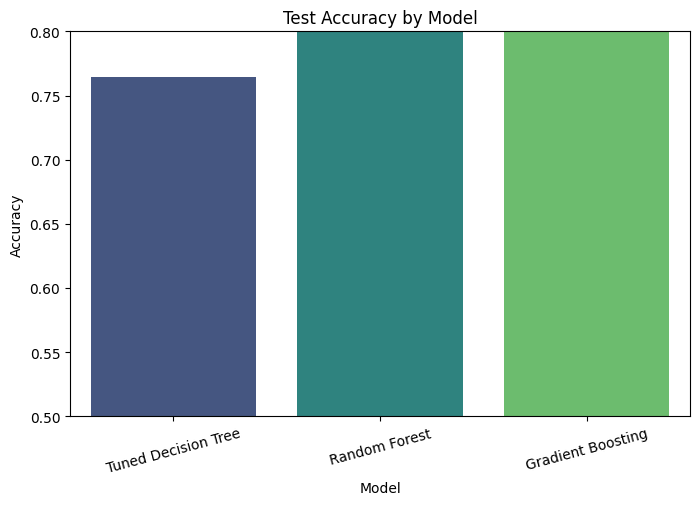

/tmp/ipykernel_384/2633625152.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Estimated Profit', data=model_results, palette='magma')


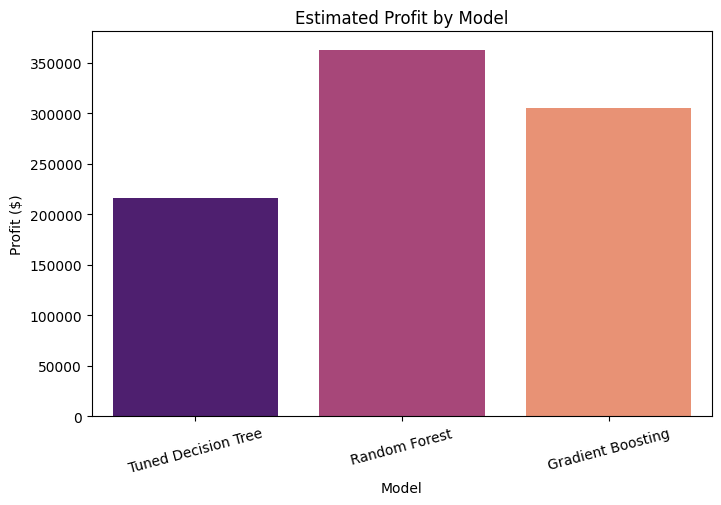

In [27]:
# 1. Extract the TP, FP, and calculate profit for all models

# Random Forest (using the variables defined in section 5.4)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(y_test, y_pred_rf).ravel()
rf_profit = (tp_rf * 75) - (fp_rf * 25)

# Gradient Boosting (using the variables defined in section 5.5)
gb_accuracy = accuracy_score(y_test, y_pred_gb)
tn_gb, fp_gb, fn_gb, tp_gb = confusion_matrix(y_test, y_pred_gb).ravel()
gb_profit = (tp_gb * 75) - (fp_gb * 25)

# Tuned Decision Tree (using the variables defined in section 5.3)
# Note: If you named your tuned variables differently, adjust them here.
tree_tp = tp_tuned
tree_fp = fp_tuned
tree_profit = profit_tuned

# 2. Create the comparison table
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [accuracy_tuned, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, tp_rf, tp_gb],
    'False Positives': [tree_fp, fp_rf, fp_gb],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

# Display the table
print("--- Model Comparison Table ---")
display(model_results)

# 3. Create a bar chart comparing test accuracy
plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Test Accuracy', data=model_results, palette='viridis')
plt.title('Test Accuracy by Model')
plt.ylabel('Accuracy')
plt.ylim(0.5, 0.8) # Set y-axis limits to make differences clearer
plt.xticks(rotation=15)
plt.show()

# 4. Create a bar chart comparing estimated profit (optional, but helpful)
plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Estimated Profit', data=model_results, palette='magma')
plt.title('Estimated Profit by Model')
plt.ylabel('Profit ($)')
plt.xticks(rotation=15)
plt.show()

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [28]:
# Add code here 🔧
# Import the new customer data
new_customer_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(new_customer_url)

# --- Apply same data prep steps as before ---

# Drop customer_id and product columns
cols_to_drop = ['customer_id', 'product']
df_new = df_new.drop(columns=cols_to_drop, errors='ignore')

# Convert female to string, then category
df_new['female'] = df_new['female'].astype(str).str.strip()

# Convert to categorical
categorical_cols = ['job', 'chk_acct', 'sav_acct', 'female']
for col in categorical_cols:
    if col in df_new.columns:
        df_new[col] = df_new[col].astype('category')

# One-hot encode using the same columns as the training data
X_new_encoded = pd.get_dummies(df_new, columns=['female', 'job', 'chk_acct', 'sav_acct'], drop_first=True)

# Align columns to ensure match with training data
X_new_encoded = X_new_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Predict using the recommended model (Random Forest)
predictions = rf_model.predict(X_new_encoded)
prediction_counts = pd.Series(predictions).value_counts()

print("--- Predictions for New Customer Data ---")
print(f"Total new customers: {len(predictions)}")
print(f"Predicted to NOT answer (False): {prediction_counts.get(False, 0)}")
print(f"Predicted to ANSWER (True): {prediction_counts.get(True, 0)}")

--- Predictions for New Customer Data ---
Total new customers: 1000
Predicted to NOT answer (False): 455
Predicted to ANSWER (True): 545


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. The Random Forest model produced the highest profit, and it was also the most accurate.
 2. A business might pick a slightly less accurate model if it's much easier to explain, faster to run, or better at avoiding a specific type of costly mistake.
 3. The Decision Tree is the easiest to explain because you can just show someone the flowchart. However, I would still recommend the Random Forest because it makes more money, and that's the most important thing for the business.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Yes, we improved profit. Calling everyone made $203,875, but our Random Forest model made an estimated $210,125 on the same data, an increase of about $6,250.

6.2 The business could use the model to prioritize which customers to call. When someone schedules a call, we can predict if they're likely to answer and focus our sales reps' time on the best leads, making the team more efficient and profitable.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"